In [1]:
from torch.utils.data import Dataset
from PIL import Image
import os
import pandas as pd
import matplotlib.pylab as plt
import torchvision.transforms.functional as TF
import numpy as np
import random
from PIL import Image, ImageDraw
from torchvision import utils

path2data="F:/Amrita_2024/DEEP LEARNING FOR SIGNAL & IMAGE _21AIE312/Python_neural network/"
path2train="F:/Amrita_2024/DEEP LEARNING FOR SIGNAL & IMAGE _21AIE312/Python_neural network/training_drion/"
#path2labels="/media/mithun/New Volume/2021_pc/disc/code/drion_training.xlsx"
path2labels=os.path.join(path2data,"drion_training.xlsx")
labels_df=pd.read_excel(path2labels)
labels_df.head()
labels_df.tail()
print(labels_df['label'].value_counts())
imgName=labels_df["imgName"]


label
0    47
1    39
Name: count, dtype: int64


86
68
----------
18
68
18


C:\Users\Admin\AppData\Local\Temp\ipykernel_7316\906431389.py:49: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  npimg = np.array(img)


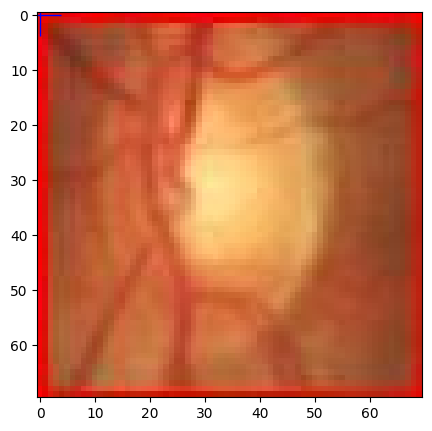

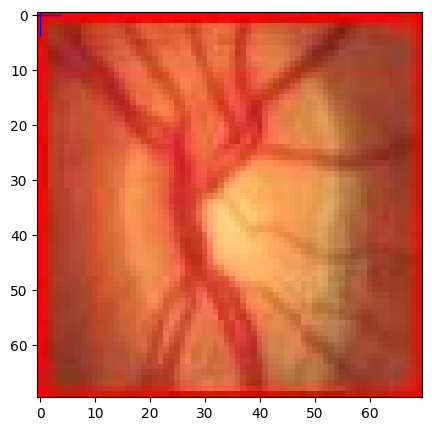

In [2]:
class AMD_dataset(Dataset):
      def __init__(self, path2data,transform):
           path2labels=os.path.join(path2data,"drion_training.xlsx")
           labels_df=pd.read_excel(path2labels)
           self.labels = labels_df[["label"]].values
           self.imgName=labels_df["imgName"]
           self.ids=labels_df.index
           self.fullPath2img=[0]*len(self.ids)
           for id_ in self.ids:
               self.fullPath2img[id_-1]=os.path.join(path2data,"training_drion",imgName[id_])
           self.transform = transform
                    
           
      def __len__(self):
          return len(self.labels)
      
      def __getitem__(self, idx):
          #image = Image.open(self.fullPath2img)
          image = Image.open(self.fullPath2img[idx],mode="r")
          label= self.labels[idx]
          #image = self.transform(image)
          image,label = self.transform(image,label)
          return image, self.labels[idx]
     
        
def transformer(image, label):
    image=TF.to_tensor(image)
    return image, label

amd_ds1=AMD_dataset(path2data,transformer)
amd_ds2=AMD_dataset(path2data,transformer)
print(len(amd_ds1))

from sklearn.model_selection import ShuffleSplit
sss = ShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
indices=range(len(amd_ds1))
for train_index, val_index in sss.split(indices):
    print(len(train_index))
    print("-"*10)
    print(len(val_index))
from torch.utils.data import Subset
train_ds=Subset(amd_ds1,train_index)
print(len(train_ds))
val_ds=Subset(amd_ds2,val_index)
print(len(val_ds))


def show(img,label):
    npimg = np.array(img)
    npimg_tr=np.transpose(npimg, (1,2,0))
    plt.imshow(npimg_tr)
    #plt.imshow(np.asarray(img))
    if label is not None:
        x=label
        plt.plot(x,'b+',markersize=30)


plt.figure(figsize=(5,5))
for img,label in train_ds:
    show(img,label)
    break 

plt.figure(figsize=(5,5))
for img,label in val_ds:
    show(img,label)
    break  

In [3]:
import torch
from torch.utils.data import DataLoader
train_dl = DataLoader(train_ds, batch_size=5, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=3, shuffle=True)

for img_b, label_b in train_dl:
    print(img_b.shape,img_b.dtype)
    print(label_b.shape)
    break

for img_b, label_b in val_dl:
    print(img_b.shape,img_b.dtype)
    #label_b=torch.stack(label_b,1)
    label_b=label_b.type(torch.float32)
    print(label_b.shape,label_b.dtype)
    break

for x,y in train_dl:
    print(x.shape,y)
    break
for x, y in train_dl:
    print(x.shape)
    print(y.shape)
    
def accuracy(labels, out):
    return np.sum(out==labels)/float(len(labels))

import torch.nn as nn          
def findConv2dOutShape(H_in,W_in,conv,pool=2):# get conv arguments
    kernel_size=conv.kernel_size
    stride=conv.stride
    padding=conv.padding
    dilation=conv.dilation
    H_out=np.floor((H_in+2*padding[0]-dilation[0]*(kernel_size[0]-1)-1)/stride[0]+1)
    W_out=np.floor((W_in+2*padding[1]-dilation[1]*(kernel_size[1]-1)-1)/stride[1]+1)
    if pool:
       H_out/=pool
       W_out/=pool
    return int(H_out),int(W_out) 


import torch.nn.functional as F
class Net(nn.Module):
      def __init__(self, params):
          super(Net, self).__init__()
          C_in,H_in,W_in=params["input_shape"]
          init_f=params["initial_filters"]
          num_fc1=params["num_fc1"]
          num_classes=params["num_classes"]
          self.dropout_rate=params["dropout_rate"]
          self.conv1 = nn.Conv2d(C_in, init_f, kernel_size=3)
          h,w=findConv2dOutShape(H_in,W_in,self.conv1)
          self.conv2 = nn.Conv2d(init_f, 2*init_f, kernel_size=3)
          h,w=findConv2dOutShape(h,w,self.conv2)
          self.conv3 = nn.Conv2d(2*init_f, 4*init_f, kernel_size=3)
          h,w=findConv2dOutShape(h,w,self.conv3)
          self.conv4 = nn.Conv2d(4*init_f, 8*init_f, kernel_size=3)
          h,w=findConv2dOutShape(h,w,self.conv4)
# compute the flatten size
          self.num_flatten=h*w*8*init_f
          self.fc1 = nn.Linear(self.num_flatten, num_fc1)
          self.fc2 = nn.Linear(num_fc1, num_classes)
      def forward(self, x):
          x = F.relu(self.conv1(x))
          x = F.max_pool2d(x, 2, 2)
          x = F.relu(self.conv2(x))
          x = F.max_pool2d(x, 2, 2)
          x = F.relu(self.conv3(x))
          x = F.max_pool2d(x, 2, 2)
          x = F.relu(self.conv4(x))
          x = F.max_pool2d(x, 2, 2)
          x = x.view(-1, self.num_flatten)
          x = F.relu(self.fc1(x))
          x=F.dropout(x, self.dropout_rate, training= self.training)
          x = self.fc2(x)
          return F.log_softmax(x,dim=1)
params_model={
"input_shape": (3,70,70),
"initial_filters": 8,
"num_fc1": 100,
"dropout_rate": 0.25,
"num_classes": 2,
}
model = Net(params_model)
if torch.cuda.is_available():
   device = torch.device("cuda")
   model=model.to(device)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# cnn_model = Net(params_model)
# cnn_model = cnn_model.to(device)
print(model)
print(next(model.parameters()).device)

from torchsummary import summary
summary(model, input_size=(3, 70, 70),device=device.type)

torch.Size([5, 3, 70, 70]) torch.float32
torch.Size([5, 1])
torch.Size([3, 3, 70, 70]) torch.float32
torch.Size([3, 1]) torch.float32
torch.Size([5, 3, 70, 70]) tensor([[1],
        [1],
        [0],
        [1],
        [0]])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([5, 3, 70, 70])
torch.Size([5, 1])
torch.Size([3, 3, 70, 70])
torch.Size([3, 1])
Net(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1))
  (co

In [7]:
loss_func = nn.NLLLoss(reduction="sum")
from torch import optim
opt = optim.Adam(model.parameters(), lr=3e-4)
# get learning rate
def get_lr(opt):
    for param_group in opt.param_groups:
        return param_group['lr']
    
current_lr=get_lr(opt)
print('current lr={}'.format(current_lr))
from torch.optim.lr_scheduler import ReduceLROnPlateau
# define learning rate scheduler
lr_scheduler = ReduceLROnPlateau(opt, mode='min',factor=0.5,patience=20)
for i in range(100):
    lr_scheduler.step(1)

current lr=0.0003


In [8]:
def metrics_batch(output, target):
# get output class
    pred = output.argmax(dim=1, keepdim=True)
# compare output class with target class
    corrects=pred.eq(target.view_as(pred)).sum().item()
    return corrects

def loss_batch(loss_func, output, target, opt=None):
    loss = loss_func(output, target)
    with torch.no_grad():
         metric_b = metrics_batch(output,target)
    if opt is not None:
       opt.zero_grad()
       loss.backward()
       opt.step()
    return loss.item(), metric_b


def loss_epoch(model,loss_func,dataset_dl,sanity_check=False,opt=None):
    running_loss=0.0
    running_metric=0.0
    len_data=len(dataset_dl.dataset)
    for xb, yb in dataset_dl:
# move batch to device
        xb=xb.to(device)
        yb=yb.type(torch.float32).to(device)
# get model output
        output=model(xb.to(device))
# get loss per batch
        loss_b,metric_b=loss_batch(loss_func, output, yb, opt)
        # update running loss
        running_loss+=loss_b
# update running metric
        if metric_b is not None:
           running_metric+=metric_b
# break the loop in case of sanity check
        if sanity_check is True:
           break
     #average loss value
    loss=running_loss/float(len_data)
# average metric value
    metric=running_metric/float(len_data)
    return loss, metric


Epoch 0/99, current lr=0.0001
Copied best model weights!
Epoch 1/99, current lr=0.0001
Copied best model weights!
Epoch 2/99, current lr=0.0001
Epoch 3/99, current lr=0.0001
Copied best model weights!
Epoch 4/99, current lr=0.0001
Copied best model weights!
Epoch 5/99, current lr=0.0001
Epoch 6/99, current lr=0.0001
Epoch 7/99, current lr=0.0001
Epoch 8/99, current lr=0.0001
Epoch 9/99, current lr=0.0001
Epoch 10/99, current lr=0.0001
Epoch 11/99, current lr=0.0001
Epoch 12/99, current lr=0.0001
Copied best model weights!
Epoch 13/99, current lr=0.0001
Epoch 14/99, current lr=0.0001
Epoch 15/99, current lr=0.0001
Epoch 16/99, current lr=0.0001
Epoch 17/99, current lr=0.0001
Epoch 18/99, current lr=0.0001
Epoch 19/99, current lr=0.0001
Epoch 20/99, current lr=0.0001
Epoch 21/99, current lr=0.0001
Epoch 22/99, current lr=0.0001
Epoch 23/99, current lr=0.0001
Epoch 24/99, current lr=0.0001
Epoch 25/99, current lr=0.0001
Epoch 26/99, current lr=0.0001
Epoch 27/99, current lr=0.0001
Epoch 2

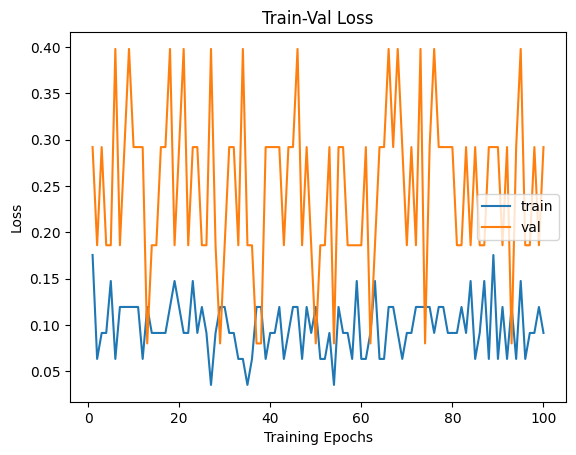

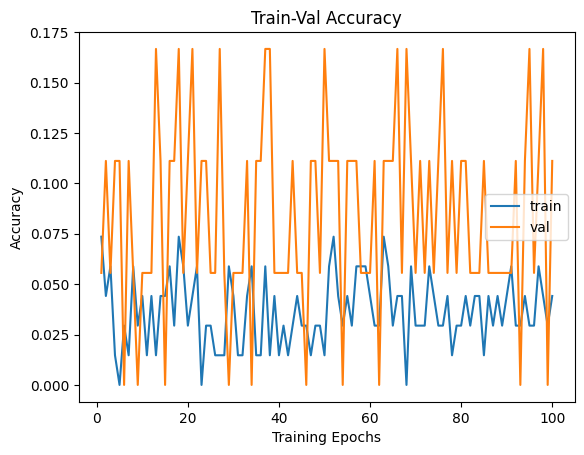

In [12]:
import copy
def train_val(model, params):
    num_epochs=params["num_epochs"]
    loss_func=params["loss_func"]
    opt=params["optimizer"]
    train_dl=params["train_dl"]
    val_dl=params["val_dl"]
    sanity_check=params["sanity_check"]
    lr_scheduler=params["lr_scheduler"]
    path2weights=params["path2weights"]
#We continue the function by defining two Python dictionaries to keep track of theloss and metric values:
    loss_history={"train": [],"val": [],}
    metric_history={"train": [],"val": [],} 
    best_model_wts = copy.deepcopy(model.state_dict())
    best_loss=float('inf')
    for epoch in range(num_epochs):
        current_lr=get_lr(opt)
        print('Epoch {}/{}, current lr={}'.format(epoch, num_epochs- 1, current_lr))
        model.train()
        train_loss,train_metric=loss_epoch(model,loss_func,train_dl,sanity_check,opt)
        loss_history["train"].append(train_loss)
        metric_history["train"].append(train_metric)
#The loop continues with the evaluation snippet:
        model.eval()
        with torch.no_grad():
             val_loss,val_metric=loss_epoch(model,loss_func,val_dl,sanity_check)
        loss_history["val"].append(val_loss)
        metric_history["val"].append(val_metric)
        if val_loss < best_loss:
           best_loss = val_loss
           best_model_wts = copy.deepcopy(model.state_dict())
           torch.save(model.state_dict(), path2weights)
           print("Copied best model weights!")
        lr_scheduler.step(val_loss)
        if current_lr != get_lr(opt):
           print("Loading best model weights!")
           model.load_state_dict(best_model_wts)
           print("train loss: %.6f, accuracy: %.2f" %(train_loss,100*train_metric))
           print("val loss: %.6f, accuracy: %.2f" %(val_loss,100*val_metric))
           print("-"*10)
           model.load_state_dict(best_model_wts)
    return model, loss_history, metric_history  

loss_func=nn.SmoothL1Loss(reduction="sum")
opt = optim.Adam(model.parameters(), lr=1e-4)
lr_scheduler = ReduceLROnPlateau(opt, mode='min',factor=0.5,patience=20)
path2models= "F:/Amrita_2024/DEEP LEARNING FOR SIGNAL & IMAGE _21AIE312/Python_neural network/models/"
if not os.path.exists(path2models):
   os.mkdir(path2models)
params_train={
"num_epochs": 100,
"optimizer": opt,
"loss_func": loss_func,
"train_dl": train_dl,
"val_dl": val_dl,
"sanity_check": True,
"lr_scheduler": lr_scheduler,
"path2weights": path2models+"weights_smoothl1.pt",
}
model,loss_hist,metric_hist=train_val(model,params_train)    
num_epochs=params_train["num_epochs"]
plt.title("Train-Val Loss")
plt.plot(range(1,num_epochs+1),loss_hist["train"],label="train")
plt.plot(range(1,num_epochs+1),loss_hist["val"],label="val")
plt.ylabel("Loss")    
plt.xlabel("Training Epochs")
plt.legend()
plt.show()    
plt.title("Train-Val Accuracy")
plt.plot(range(1,num_epochs+1),metric_hist["train"],label="train")
plt.plot(range(1,num_epochs+1),metric_hist["val"],label="val")
plt.ylabel("Accuracy")
plt.xlabel("Training Epochs")
plt.legend()
plt.show()    
params_model={
"input_shape": (3,70,70),
"initial_filters": 8,
"num_fc1": 100,
"dropout_rate": 0.25,
"num_classes": 2,
}

cnn_model = Net(params_model)

In [13]:
path2weights="F:/Amrita_2024/DEEP LEARNING FOR SIGNAL & IMAGE _21AIE312/Python_neural network/models/weights_smoothl1.pt"
cnn_model.load_state_dict(torch.load(path2weights))
cnn_model.eval()
if torch.cuda.is_available():
   device = torch.device("cuda")
   cnn_model=cnn_model.to(device)


import time
def deploy_model(model,dataset,device,num_classes=2,sanity_check=False):
    len_data=len(dataset)
# initialize output tensor on CPU: due to GPU memory limits
    y_out=torch.zeros(len_data,num_classes)
# initialize ground truth on CPU: due to GPU memory limits
    y_gt=np.zeros((len_data),dtype="uint8")
# move model to device
    model=model.to(device)
    elapsed_times=[]
    with torch.no_grad():
        for i in range(len_data):
            x,y=dataset[i]
            y_gt[i]=y
            start=time.time()
            y_out[i]=model(x.unsqueeze(0).to(device))
            elapsed=time.time()-start
            elapsed_times.append(elapsed)
            if sanity_check is True:
               break
    inference_time=np.mean(elapsed_times)*1000
    print("average inference time per image on %s: %.2f ms "%(device,inference_time))
    return y_out.numpy(),y_gt


In [14]:
# deploy model
y_out,y_gt=deploy_model(cnn_model,val_ds,device=device,sanity_check=False)
print(y_out.shape,y_gt.shape)
from sklearn.metrics import accuracy_score
# get predictions
y_pred = np.argmax(y_out,axis=1)
print(y_pred.shape,y_gt.shape)
# compute accuracy
acc=accuracy_score(y_pred,y_gt)
print("accuracy: %.2f" %acc)



average inference time per image on cpu: 2.44 ms 
(18, 2) (18,)
(18,) (18,)
accuracy: 0.50


C:\Users\Admin\AppData\Local\Temp\ipykernel_15372\2535341761.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_gt[i]=y


10
average inference time per image on cpu: 1.80 ms 
average inference time per image on cpu: 1.60 ms 
(10,)
accuracy: 0.50
(10,) (10,)
accuracy: 0.50
image indices: [0 5 9 8]
torch.Size([3, 74, 290])
[np.int64(1), np.int64(1), np.int64(1), np.int64(1)]


C:\Users\Admin\AppData\Local\Temp\ipykernel_15372\2535341761.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_gt[i]=y
C:\Users\Admin\AppData\Local\Temp\ipykernel_15372\906431389.py:49: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  npimg = np.array(img)


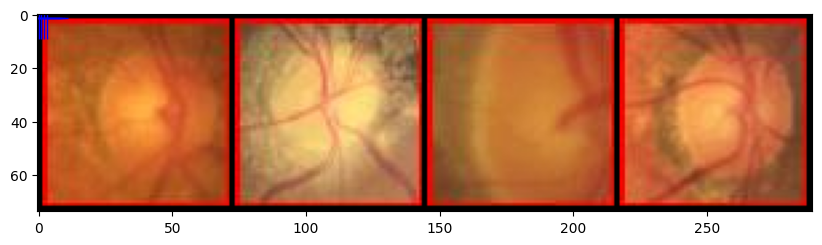

In [15]:
path2data_test="F:/Amrita_2024/DEEP LEARNING FOR SIGNAL & IMAGE _21AIE312/Python_neural network/"
path2labels=os.path.join(path2data,"drion_testing.xlsx")
labels_df=pd.read_excel(path2labels)
labels_df.head()
class AMD_dataset1(Dataset):
      def __init__(self, path2data,transform):
           path2labels=os.path.join(path2data,"drion_testing.xlsx")
           labels_df=pd.read_excel(path2labels)
           self.labels = labels_df[["label"]].values
           self.imgName=labels_df["imgName"]
           self.ids=labels_df.index
           self.fullPath2img=[0]*len(self.ids)
           for id_ in self.ids:
               self.fullPath2img[id_-1]=os.path.join(path2data,"test_cropped",imgName[id_])
           self.transform = transform
                    
           
      def __len__(self):
          return len(self.labels)
      
      def __getitem__(self, idx):
          #image = Image.open(self.fullPath2img)
          image = Image.open(self.fullPath2img[idx],mode="r")
          label= self.labels[idx]
          image,label = self.transform(image,label)
          return image, label
     
histo_test = AMD_dataset1(path2data_test,transformer)
print(len(histo_test))
y_test_out,y_gt=deploy_model(cnn_model,histo_test, device,sanity_check=False)
y_test_out,_=deploy_model(cnn_model,histo_test, device,sanity_check=False)
y_test_pred=np.argmax(y_test_out,axis=1)
print(y_test_pred.shape)
acc=accuracy(y_test_pred,y_gt)
print("accuracy: %.2f" %acc)

from sklearn.metrics import accuracy_score
# get predictions
y_pred = np.argmax(y_test_out,axis=1)
print(y_pred.shape,y_gt.shape)
# compute accuracy
acc=accuracy_score(y_pred,y_gt)
print("accuracy: %.2f" %acc)

grid_size=4
rnd_inds=np.random.randint(0,len(histo_test),grid_size)
print("image indices:",rnd_inds)
x_grid_test=[histo_test[i][0] for i in range(grid_size)]
y_grid_test=[y_test_pred[i] for i in range(grid_size)]
x_grid_test=utils.make_grid(x_grid_test, nrow=4, padding=2)
print(x_grid_test.shape)
plt.rcParams['figure.figsize'] = (10.0, 5)
show(x_grid_test,y_grid_test)
print(y_grid_test)
